Epoch [1/5], Step [100/938], Loss: 2.9077
Epoch [1/5], Step [200/938], Loss: 3.2095
Epoch [1/5], Step [300/938], Loss: 3.4927
Epoch [1/5], Step [400/938], Loss: 3.8617
Epoch [1/5], Step [500/938], Loss: 3.4830
Epoch [1/5], Step [600/938], Loss: 5.6354
Epoch [1/5], Step [700/938], Loss: 4.9595
Epoch [1/5], Step [800/938], Loss: 10.4154
Epoch [1/5], Step [900/938], Loss: 18.0171


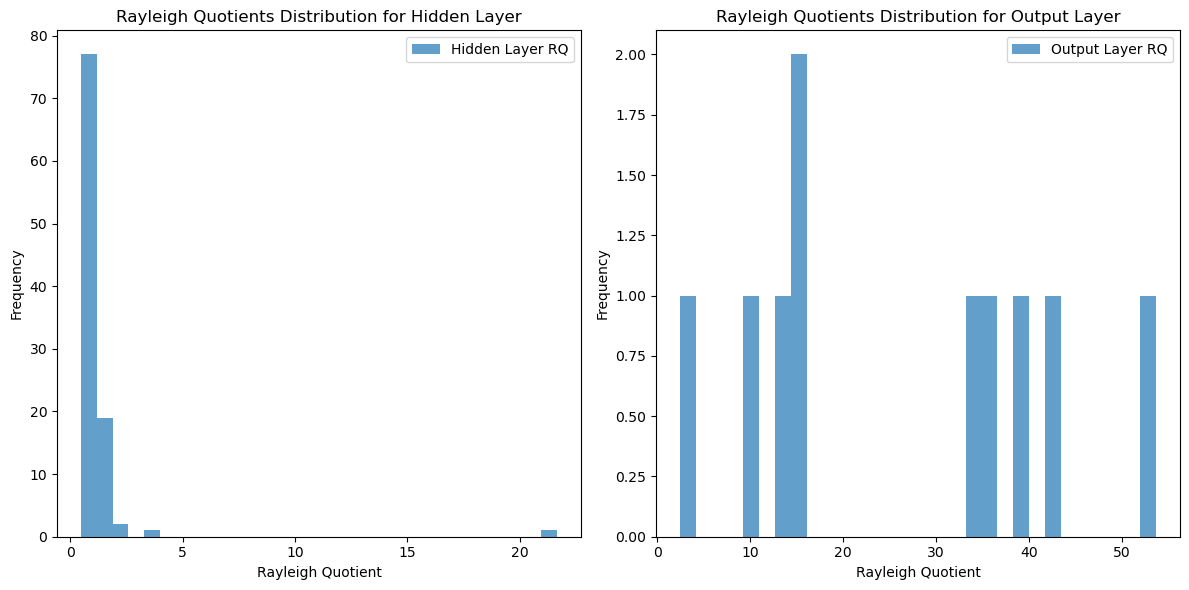

Epoch [2/5], Step [100/938], Loss: 47.4060
Epoch [2/5], Step [200/938], Loss: 67.7570
Epoch [2/5], Step [300/938], Loss: 171.4394
Epoch [2/5], Step [400/938], Loss: 235.7047
Epoch [2/5], Step [500/938], Loss: 493.8445
Epoch [2/5], Step [600/938], Loss: 1077.3894
Epoch [2/5], Step [700/938], Loss: 2330.7410
Epoch [2/5], Step [800/938], Loss: 4065.4819
Epoch [2/5], Step [900/938], Loss: 7671.5674


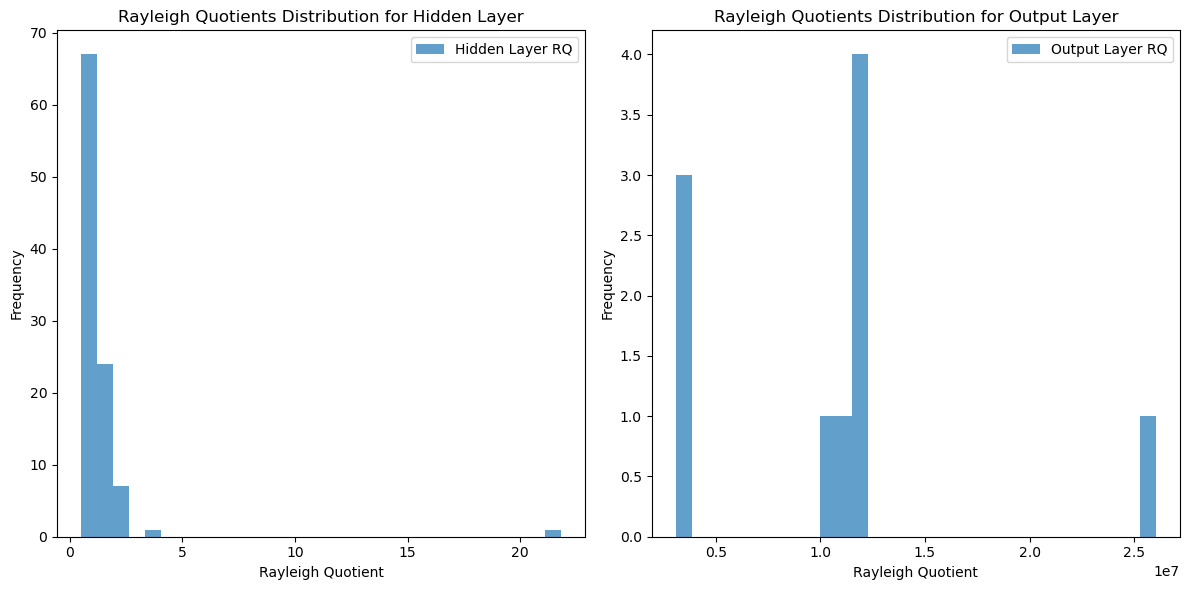

Epoch [3/5], Step [100/938], Loss: 25201.6191
Epoch [3/5], Step [200/938], Loss: 42262.6211
Epoch [3/5], Step [300/938], Loss: 85446.9922
Epoch [3/5], Step [400/938], Loss: 209070.3438
Epoch [3/5], Step [500/938], Loss: 477794.3438
Epoch [3/5], Step [600/938], Loss: 661783.5625
Epoch [3/5], Step [700/938], Loss: 1602815.5000
Epoch [3/5], Step [800/938], Loss: 2593326.7500
Epoch [3/5], Step [900/938], Loss: 5716762.5000


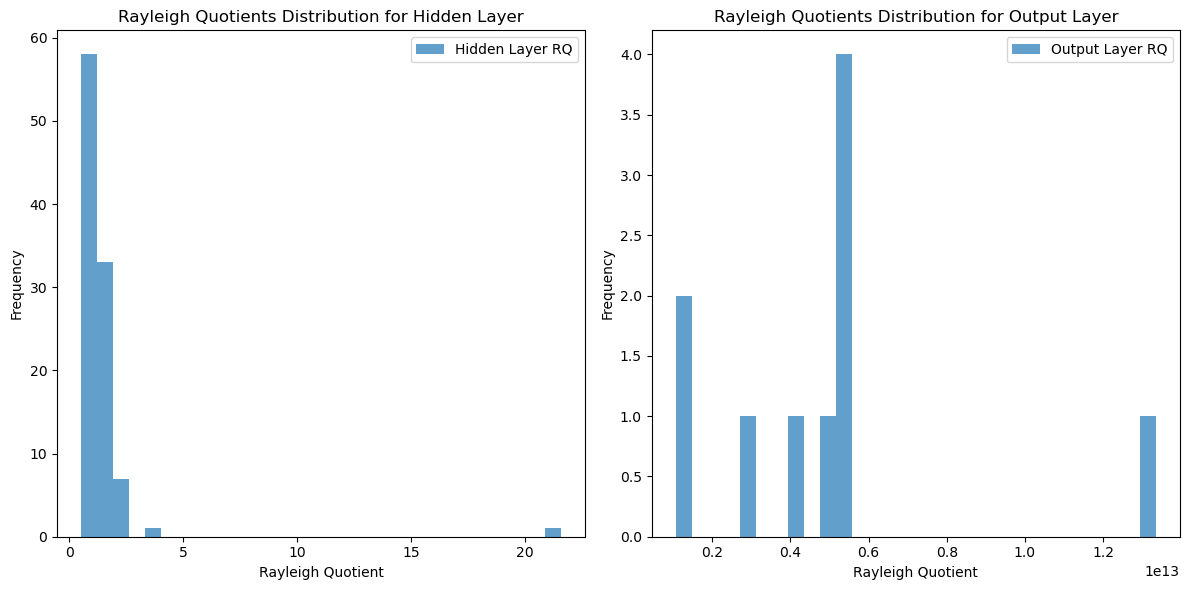

Epoch [4/5], Step [100/938], Loss: 13962573.0000
Epoch [4/5], Step [200/938], Loss: 36989300.0000
Epoch [4/5], Step [300/938], Loss: 54285224.0000
Epoch [4/5], Step [400/938], Loss: 123549392.0000
Epoch [4/5], Step [500/938], Loss: 205582848.0000
Epoch [4/5], Step [600/938], Loss: 511099616.0000
Epoch [4/5], Step [700/938], Loss: 751314688.0000
Epoch [4/5], Step [800/938], Loss: 1385653504.0000
Epoch [4/5], Step [900/938], Loss: 3763192576.0000


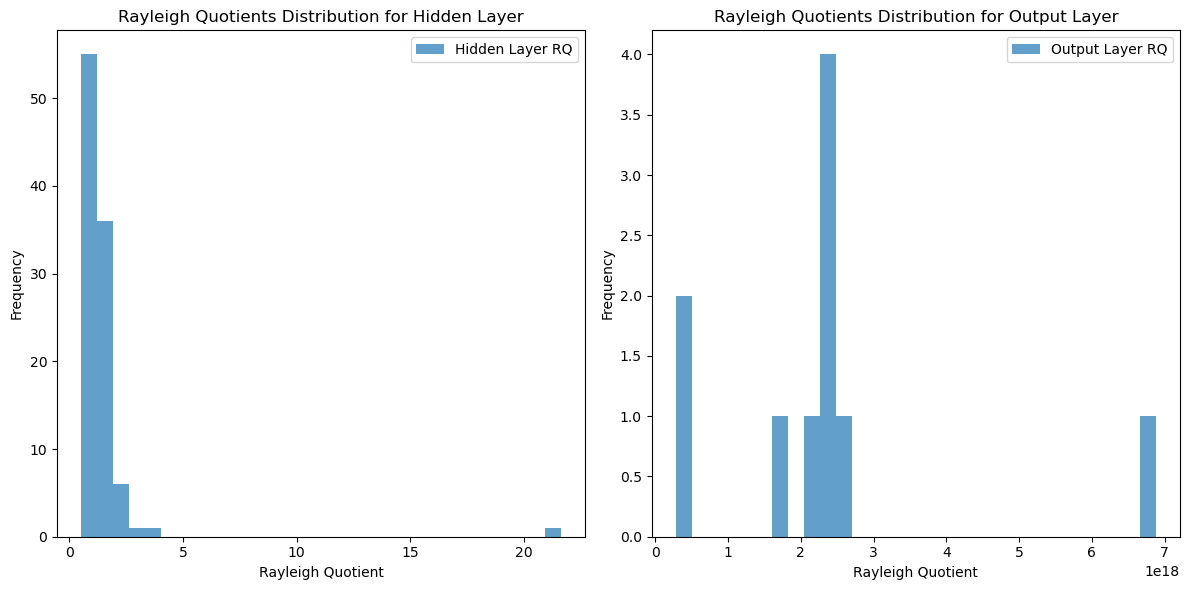

Epoch [5/5], Step [100/938], Loss: 9119659008.0000
Epoch [5/5], Step [200/938], Loss: 17003829248.0000
Epoch [5/5], Step [300/938], Loss: 29230579712.0000
Epoch [5/5], Step [400/938], Loss: 61626925056.0000


KeyboardInterrupt: 

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

# Enable anomaly detection to catch operations that cause NaNs
torch.autograd.set_detect_anomaly(True)

# Define the MLP model with Sanger's learning rule
class SangerMLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SangerMLP, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size

        # Define layers
        self.hidden_layer = nn.Linear(input_size, hidden_size, bias=False)
        self.output_layer = nn.Linear(hidden_size, output_size, bias=False)

        # Initialize weights
        nn.init.kaiming_uniform_(self.hidden_layer.weight, nonlinearity='relu')
        nn.init.kaiming_uniform_(self.output_layer.weight, nonlinearity='linear')

    def forward(self, x):
        # Forward pass through hidden layer
        hidden_output = torch.relu(self.hidden_layer(x))
        
        # Forward pass through output layer
        output = self.output_layer(hidden_output)
        
        return output, hidden_output

# Define Sanger's learning rule for weight updates
def sanger_update(hidden_layer, inputs, hidden_outputs, learning_rate):
    epsilon = 1e-8  # Small epsilon to avoid division by zero
    with torch.no_grad():
        for i in range(hidden_layer.weight.size(0)):
            y_i = hidden_outputs[:, i].unsqueeze(1)  # Output of the i-th neuron
            w_i = hidden_layer.weight[i].unsqueeze(0)  # Weight of the i-th neuron

            # Calculate the projection of inputs onto the learned components
            if i > 0:
                projection = torch.matmul(hidden_outputs[:, :i], hidden_layer.weight[:i])
            else:
                projection = torch.zeros_like(inputs)

            # Update rule based on Sanger's learning rule
            delta_w = learning_rate * torch.matmul((inputs - projection).T, y_i) / (torch.norm(inputs - projection) + epsilon)
            hidden_layer.weight[i] += delta_w.squeeze(1)  # Correct dimension by squeezing

            # Check for NaNs in weights
            if torch.isnan(hidden_layer.weight[i]).any():
                print(f"NaN detected in weights of neuron {i}")
                return False  # Signal to stop training

    return True

# Compute the covariance matrix of input data
def compute_covariance_matrix(inputs):
    """Compute covariance matrix of the input data."""
    mean = torch.mean(inputs, dim=0)
    centered_data = inputs - mean
    covariance_matrix = torch.matmul(centered_data.t(), centered_data) / (inputs.size(0) - 1)
    return covariance_matrix

# Compute Rayleigh quotients for each layer's weights
def compute_rayleigh_quotients(weights, covariance_matrix):
    """Compute Rayleigh quotient for each weight vector in the layer."""
    rayleigh_quotients = []
    for w in weights:
        w = w.unsqueeze(1)  # Convert to column vector
        numerator = torch.matmul(w.t(), torch.matmul(covariance_matrix, w))
        denominator = torch.matmul(w.t(), w) + 1e-8  # Add epsilon to avoid division by zero
        
        rq = (numerator / denominator).item()
        rayleigh_quotients.append(rq)
    
    return rayleigh_quotients

# Load MNIST dataset
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)

# Initialize model, define hyperparameters
input_size = 28 * 28  # MNIST images are 28x28
hidden_size = 100  # Number of neurons in hidden layer
output_size = 10  # Number of classes for MNIST
learning_rate = 0.0001  # Further lowered learning rate
weight_decay = 1e-4  # L2 regularization
num_epochs = 5
max_grad_norm = 1.0  # Gradient clipping threshold

model = SangerMLP(input_size, hidden_size, output_size)

# Training loop
for epoch in range(num_epochs):
    all_hidden_outputs = []  # Store hidden layer outputs for RQ computation
    all_inputs = []  # Store inputs for RQ computation
    for i, (images, labels) in enumerate(train_loader):
        images = images.view(-1, 28*28)  # Flatten images
        
        # Forward pass
        outputs, hidden_outputs = model(images)
        all_hidden_outputs.append(hidden_outputs)
        all_inputs.append(images)
        
        # Compute Sanger's learning rule update for hidden layer
        if not sanger_update(model.hidden_layer, images, hidden_outputs, learning_rate):
            print("Stopping training due to NaNs in weights.")
            break
        
        # For simplicity, we will not update the output layer weights with Sanger's rule.
        # Instead, use standard gradient descent for output layer
        criterion = nn.CrossEntropyLoss()
        loss = criterion(outputs, labels) + weight_decay * model.output_layer.weight.norm(2)
        
        # Check if loss is NaN
        if torch.isnan(loss):
            print("Loss became NaN. Stopping training.")
            break
        
        # Zero gradients, backward pass, and update weights for the output layer
        model.output_layer.zero_grad()
        loss.backward()
        
        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.output_layer.parameters(), max_grad_norm)
        
        with torch.no_grad():
            for param in model.output_layer.parameters():
                param -= learning_rate * param.grad

        if (i + 1) % 100 == 0:
            print(f'Epoch [{epoch + 1}/{num_epochs}], Step [{i + 1}/{len(train_loader)}], Loss: {loss.item():.4f}')
    
    # Check if NaN appeared in loss during training
    if torch.isnan(loss) or not sanger_update(model.hidden_layer, images, hidden_outputs, learning_rate):
        break
    
    # Convert lists to tensors for covariance matrix calculation
    all_hidden_outputs = torch.cat(all_hidden_outputs, dim=0)
    all_inputs = torch.cat(all_inputs, dim=0)
    
    # Compute covariance matrices
    input_covariance = compute_covariance_matrix(all_inputs)
    hidden_covariance = compute_covariance_matrix(all_hidden_outputs)
    
    # Compute Rayleigh quotients for each layer
    input_rayleigh_quotients = compute_rayleigh_quotients(model.hidden_layer.weight, input_covariance)
    hidden_rayleigh_quotients = compute_rayleigh_quotients(model.output_layer.weight, hidden_covariance)
    
    # Plot the distribution of Rayleigh quotients
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.hist(input_rayleigh_quotients, bins=30, alpha=0.7, label='Hidden Layer RQ')
    plt.xlabel('Rayleigh Quotient')
    plt.ylabel('Frequency')
    plt.title('Rayleigh Quotients Distribution for Hidden Layer')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.hist(hidden_rayleigh_quotients, bins=30, alpha=0.7, label='Output Layer RQ')
    plt.xlabel('Rayleigh Quotient')
    plt.ylabel('Frequency')
    plt.title('Rayleigh Quotients Distribution for Output Layer')
    plt.legend()

    plt.tight_layout()
    plt.show()